# Projekt 1 – Rating/Scoring: przygotowanie danych (pkt 3.1 i 3.2)

**Notebook 01: walidacja, podziały, kontrola leakage, jakość danych, EDA i przygotowanie cech.**

Zawartość:
1. Konfiguracja i wczytanie danych
2. Podziały danych i schemat walidacji (3.1)
3. Kontrola data leakage (3.1)
4. Jakość danych – Data Quality (3.2)
5. EDA – wyłącznie na zbiorze treningowym (3.2)
6. Przygotowanie cech: capping, imputacja, binning monotoniczny, WoE, selekcja (3.2)
7. Test poprawności pipeline'u: CV bez leakage + test permutacji etykiet
8. Zapis artefaktów (podziały, dopasowane transformery, manifest cech)

**Zasady:** zbiór testowy jest tylko wydzielany i zapisywany – nie oglądamy go w EDA, nie dopasowujemy na nim niczego i nie liczymy na nim metryk. Wszystkie transformacje z parametrami uczonymi z danych (kwantyle, mediany, biny, WoE, selekcja cech) są w `src/preprocessing.py` i dopasowywane wyłącznie przez `.fit()` na zbiorze/foldzie treningowym.

## 1. Konfiguracja i wczytanie danych

In [1]:
import os, sys, json, hashlib, warnings, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
import joblib, sklearn

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 200, "display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid")

SEED = 42
TARGET = "default"
DATA_PATH = "zbiór_5.csv"          # <- w razie potrzeby zmień ścieżkę
ART_DIR = "artifacts"              # tu trafiają podziały, transformery, manifest
for d in (ART_DIR, "src", "figures"):
    os.makedirs(d, exist_ok=True)

In [2]:
%%writefile src/preprocessing.py
"""
Transformery cech do projektu 1 (rating/scoring).

Zasada nadrzedna: KAZDA transformacja z parametrami uczonymi z danych (kwantyle, mediany,
biny, WoE, selekcja cech) jest dopasowywana wylacznie w metodzie .fit() na zbiorze
treningowym (albo na foldzie treningowym w CV), a na pozostalych zbiorach tylko .transform().

Konwencja WoE: WoE = ln(%bad / %good)  ->  WoE > 0 oznacza WYZSZE ryzyko defaultu.
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin


# ----------------------------------------------------------------------------------------
# Transformacje bezstanowe (bez uczenia parametrow) - bezpieczne do uzycia przed podzialem
# ----------------------------------------------------------------------------------------
def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def add_stateless_features(df, level_cols=()):
    """Cechy wyliczane wiersz po wierszu (bez parametrow uczonych z danych)."""
    out = df.copy()
    out["pkd_div"] = (pd.to_numeric(out["pkdKod"], errors="coerce") // 100).astype("Int64").astype(str).str.zfill(2)
    out["forma_wl"] = out["formaWlasnosci_Symbol"].astype(str)
    out["log_aktywa"] = np.log1p(out["Aktywa"].clip(lower=0))
    for c in level_cols:  # pozycje kwotowe -> signed log (kwoty sa silnie prawoskosne)
        out[f"slog_{c}"] = signed_log1p(out[c])
    return out


# ----------------------------------------------------------------------------------------
# Czyszczenie cech numerycznych
# ----------------------------------------------------------------------------------------
class FinancialCleaner(BaseEstimator, TransformerMixin):
    """inf -> NaN, usuniecie cech zbyt rzadkich / quasi-stalych, winsoryzacja, (opcj.) imputacja,
    wskazniki brakow, standaryzacja. Wszystkie parametry wyznaczane w fit()."""

    def __init__(self, max_missing=0.90, quasi_const=0.99, winsor=(0.01, 0.99),
                 impute=True, indicator_min=0.02, scale=False):
        self.max_missing = max_missing
        self.quasi_const = quasi_const
        self.winsor = winsor
        self.impute = impute
        self.indicator_min = indicator_min
        self.scale = scale

    @staticmethod
    def _inf(X):
        return X.replace([np.inf, -np.inf], np.nan)

    def fit(self, X, y=None):
        X = self._inf(X.astype(float))
        miss = X.isna().mean()
        nn = X.notna().sum().clip(lower=1)
        top_share = X.apply(lambda s: s.value_counts(dropna=True).iloc[0] if s.notna().any() else 0) / nn
        drop_missing = miss[miss > self.max_missing].index.tolist()
        drop_const = [c for c in X.columns if c not in drop_missing and top_share[c] >= self.quasi_const]
        self.dropped_ = {"za_duzo_brakow": drop_missing, "quasi_stale": drop_const}
        self.cols_ = [c for c in X.columns if c not in drop_missing + drop_const]
        X = X[self.cols_]
        if self.winsor is not None:
            self.lo_ = X.quantile(self.winsor[0])
            self.hi_ = X.quantile(self.winsor[1])
            X = X.clip(self.lo_, self.hi_, axis=1)
        self.median_ = X.median()
        self.ind_cols_ = [c for c in self.cols_ if miss[c] >= self.indicator_min] if self.impute else []
        Xi = X.fillna(self.median_) if self.impute else X
        self.mean_ = Xi.mean()
        self.std_ = Xi.std().replace(0, 1.0).fillna(1.0)
        return self

    def transform(self, X):
        X = self._inf(X.astype(float)).reindex(columns=self.cols_)
        if self.winsor is not None:
            X = X.clip(self.lo_, self.hi_, axis=1)
        ind = X[self.ind_cols_].isna().astype(int).add_suffix("__isna") if self.ind_cols_ else None
        if self.impute:
            X = X.fillna(self.median_)
        if self.scale:
            X = (X - self.mean_) / self.std_
        return pd.concat([X, ind], axis=1) if ind is not None else X


# ----------------------------------------------------------------------------------------
# Kategorie: grupowanie rzadkich poziomow
# ----------------------------------------------------------------------------------------
class CategoryGrouper(BaseEstimator, TransformerMixin):
    """Poziomy o liczebnosci < min_count (liczone na zbiorze treningowym) -> 'RARE', NaN -> 'MISSING'.
    Opcjonalnie one-hot o ustalonym (z fit) zestawie kolumn."""

    def __init__(self, min_count=30, onehot=False):
        self.min_count = min_count
        self.onehot = onehot

    def fit(self, X, y=None):
        self.cols_ = list(X.columns)
        self.levels_ = {}
        for c in self.cols_:
            vc = X[c].astype(str).where(X[c].notna(), "MISSING").value_counts()
            self.levels_[c] = set(vc[vc >= self.min_count].index) | {"MISSING"}
        self.dummy_cols_ = None
        if self.onehot:
            self.dummy_cols_ = self._dummies(self._group(X)).columns.tolist()
        return self

    def _group(self, X):
        out = pd.DataFrame(index=X.index)
        for c in self.cols_:
            s = X[c].astype(str).where(X[c].notna(), "MISSING")
            out[c] = s.where(s.isin(self.levels_[c]), "RARE")
        return out

    def _dummies(self, G):
        return pd.get_dummies(G, prefix_sep="=", dtype=int)

    def transform(self, X):
        G = self._group(X)
        if not self.onehot:
            return G
        D = self._dummies(G)
        if self.dummy_cols_ is not None:
            D = D.reindex(columns=self.dummy_cols_, fill_value=0)
        return D


# ----------------------------------------------------------------------------------------
# Binning (monotoniczny) + WoE + selekcja po IV i korelacji
# ----------------------------------------------------------------------------------------
def _woe_iv(bad, good, s=0.5):
    bad, good = np.asarray(bad, float), np.asarray(good, float)
    nb = len(bad)
    pb = (bad + s) / (bad.sum() + s * nb)
    pg = (good + s) / (good.sum() + s * nb)
    woe = np.log(pb / pg)
    return woe, float(((pb - pg) * woe).sum())


def _merge(edges, tot, bad, i):
    """Laczy biny i oraz i+1."""
    edges.pop(i)
    tot[i] += tot[i + 1]; bad[i] += bad[i + 1]
    del tot[i + 1]; del bad[i + 1]


def _smooth_odds(tot, bad, s):
    """Wygladzone szanse (bad+s)/(good+s); porzadek = porzadek wygladzonego WoE (stale sie skracaja),
    wiec monotonicznosc wg tej miary gwarantuje monotoniczny WoE."""
    tot, bad = np.asarray(tot, float), np.asarray(bad, float)
    return (bad + s) / (tot - bad + s)


def _pav(edges, tot, bad, direction, s=0.5):
    edges, tot, bad = list(edges), list(tot), list(bad)
    while True:
        rate = _smooth_odds(tot, bad, s)
        viol = [i for i in range(len(rate) - 1)
                if (direction == "inc" and rate[i] > rate[i + 1]) or (direction == "dec" and rate[i] < rate[i + 1])]
        if not viol:
            return edges, tot, bad
        _merge(edges, tot, bad, viol[0])


def fit_numeric_bins(x, y, max_bins=8, min_frac=0.05, monotonic=True, n_init=20, smoothing=0.5):
    """Zwraca slownik z krawedziami binow, WoE, IV i kierunkiem zaleznosci."""
    m = x.notna().values
    xv, yv = x.values[m].astype(float), np.asarray(y)[m].astype(float)
    n_nan = int((~m).sum()); bad_nan = float(np.asarray(y)[~m].sum())
    n = len(xv)
    min_size = max(int(np.ceil(min_frac * n)), 1)
    edges = list(np.unique(np.quantile(xv, np.linspace(0, 1, n_init + 1)[1:-1]))) if n and np.ptp(xv) > 0 else []

    def counts(ed):
        idx = np.searchsorted(ed, xv, side="right")
        return (np.bincount(idx, minlength=len(ed) + 1).astype(float).tolist(),
                np.bincount(idx, weights=yv, minlength=len(ed) + 1).tolist())

    tot, bad = counts(edges)
    while len(tot) > 1 and min(tot) < min_size:            # minimalna liczebnosc binu
        i = int(np.argmin(tot)); rate = np.array(bad) / np.array(tot)
        j = min([k for k in (i - 1, i + 1) if 0 <= k < len(tot)], key=lambda k: abs(rate[k] - rate[i]))
        _merge(edges, tot, bad, min(i, j))
    direction = "n/a"
    if monotonic and len(tot) > 1:                          # monotonicznosc: wybieramy kierunek o wyzszym IV
        best = None
        for d in ("inc", "dec"):
            e2, t2, b2 = _pav(edges, tot, bad, d, smoothing)
            iv = _woe_iv(b2, np.array(t2) - np.array(b2), smoothing)[1]
            if best is None or iv > best[0]:
                best = (iv, d, e2, t2, b2)
        _, direction, edges, tot, bad = best
    while len(tot) > max_bins:                              # ograniczenie liczby binow
        lo = np.log(_smooth_odds(tot, bad, smoothing))
        _merge(edges, tot, bad, int(np.argmin(np.abs(np.diff(lo)))))
        if direction in ("inc", "dec"):                     # wygladzanie moze minimalnie zlamac monotonicznosc -> poprawka
            edges, tot, bad = (list(v) for v in _pav(edges, tot, bad, direction, smoothing))
    if n_nan > 0:                                           # osobny bin dla brakow
        tot_all, bad_all = tot + [n_nan], bad + [bad_nan]
    else:
        tot_all, bad_all = tot, bad
    woe, iv = _woe_iv(bad_all, np.array(tot_all) - np.array(bad_all), smoothing)
    nan_woe = float(woe[-1]) if n_nan > 0 else 0.0
    woe_bins = woe[:len(tot)]
    mono = bool(np.all(np.diff(woe_bins) >= -1e-12) or np.all(np.diff(woe_bins) <= 1e-12))
    return dict(kind="num", edges=np.array(edges), woe=woe_bins, nan_woe=nan_woe, iv=iv,
                n_bins=len(tot) + int(n_nan > 0), monotonic=mono, direction=direction,
                counts=np.array(tot), bads=np.array(bad), n_nan=n_nan, bad_nan=bad_nan)


def fit_categorical_woe(x, y, smoothing=0.5):
    df = pd.DataFrame({"x": x.astype(str).values, "y": np.asarray(y)})
    g = df.groupby("x")["y"].agg(["sum", "count"])
    woe, iv = _woe_iv(g["sum"].values, (g["count"] - g["sum"]).values, smoothing)
    mapping = dict(zip(g.index, woe))
    return dict(kind="cat", mapping=mapping, default=mapping.get("RARE", 0.0), iv=iv,
                n_bins=len(g), monotonic=np.nan, direction="n/a")


class WoEEncoder(BaseEstimator, TransformerMixin):
    """Binning + WoE dla cech numerycznych (monotoniczny) i kategorycznych, a nastepnie selekcja:
    IV >= iv_min oraz odfiltrowanie silnie skorelowanych cech (|r| >= corr_max, zostaje cecha o wyzszym IV)."""

    def __init__(self, cat_cols=(), max_bins=8, min_bin_frac=0.05, monotonic=True,
                 iv_min=0.02, corr_max=0.80, smoothing=0.5, max_features=None):
        self.cat_cols = cat_cols
        self.max_bins = max_bins
        self.min_bin_frac = min_bin_frac
        self.monotonic = monotonic
        self.iv_min = iv_min
        self.corr_max = corr_max
        self.smoothing = smoothing
        self.max_features = max_features

    def fit(self, X, y):
        y = np.asarray(y)
        self.bins_ = {}
        for c in X.columns:
            if c in self.cat_cols:
                self.bins_[c] = fit_categorical_woe(X[c], y, self.smoothing)
            else:
                self.bins_[c] = fit_numeric_bins(X[c], y, self.max_bins, self.min_bin_frac, self.monotonic,
                                                 smoothing=self.smoothing)
        iv = pd.Series({c: b["iv"] for c, b in self.bins_.items()}).sort_values(ascending=False)
        cand = iv[iv >= self.iv_min].index.tolist()
        Z = self._woe(X[cand]) if cand else pd.DataFrame(index=X.index)
        corr = Z.corr().abs() if cand else None
        kept = []
        for c in cand:                                     # zachlanna selekcja po IV
            if all(corr.loc[c, k] < self.corr_max for k in kept):
                kept.append(c)
            if self.max_features and len(kept) >= self.max_features:
                break
        self.selected_ = kept
        reason = {}
        for c in iv.index:
            reason[c] = ("wybrana" if c in kept else "IV < iv_min" if iv[c] < self.iv_min else "korelacja / limit cech")
        self.iv_table_ = pd.DataFrame({
            "IV": iv, "n_bins": [self.bins_[c]["n_bins"] for c in iv.index],
            "monotoniczna": [self.bins_[c]["monotonic"] for c in iv.index],
            "kierunek": [self.bins_[c]["direction"] for c in iv.index],
            "status": pd.Series(reason)})
        return self

    def _woe(self, X):
        out = {}
        for c in X.columns:
            b = self.bins_[c]
            if b["kind"] == "cat":
                out[f"woe__{c}"] = X[c].astype(str).map(b["mapping"]).fillna(b["default"]).astype(float).values
            else:
                v = X[c].values.astype(float)
                w = b["woe"][np.searchsorted(b["edges"], np.where(np.isnan(v), 0, v), side="right")]
                out[f"woe__{c}"] = np.where(np.isnan(v), b["nan_woe"], w)
        Z = pd.DataFrame(out, index=X.index)
        Z.columns = [c.replace("woe__", "", 1) for c in Z.columns]  # robocze nazwy = nazwy cech
        return Z

    def transform(self, X):
        Z = self._woe(X[self.selected_]) if self.selected_ else pd.DataFrame(index=X.index)
        return Z.add_prefix("woe__")

    def profile(self, col):
        """Tabela binow (granice, liczebnosc, default rate, WoE) - do profilowania i raportu."""
        b = self.bins_[col]
        if b["kind"] == "cat":
            return pd.Series(b["mapping"], name="WoE").sort_values().to_frame()
        e = np.r_[-np.inf, b["edges"], np.inf]
        rows = [dict(bin=f"[{e[i]:.4g}, {e[i+1]:.4g})", n=int(b["counts"][i]), defaulty=int(b["bads"][i]),
                     default_rate=b["bads"][i] / b["counts"][i], WoE=b["woe"][i]) for i in range(len(b["counts"]))]
        if b["n_nan"] > 0:
            rows.append(dict(bin="BRAK", n=b["n_nan"], defaulty=int(b["bad_nan"]),
                             default_rate=b["bad_nan"] / b["n_nan"], WoE=b["nan_woe"]))
        return pd.DataFrame(rows)


# ----------------------------------------------------------------------------------------
# Kompletny, "jednokrokowy" konstruktor cech (mode: 'woe' albo 'blackbox')
# ----------------------------------------------------------------------------------------
class ScoringFeatureBuilder(BaseEstimator, TransformerMixin):
    """mode='woe'      : czyszczenie bez imputacji -> binning monotoniczny/WoE -> selekcja (model interpretowalny)
       mode='blackbox' : czyszczenie + winsoryzacja + imputacja medianami + wskazniki brakow + one-hot
                         (opcjonalnie standaryzacja: scale=True dla SVM/sieci)."""

    def __init__(self, num_cols, cat_cols, mode="woe", min_cat=30, max_missing=0.90, quasi_const=0.99,
                 winsor=(0.01, 0.99), max_bins=8, min_bin_frac=0.05, iv_min=0.02, corr_max=0.80,
                 scale=False, max_features=None):
        self.num_cols = num_cols
        self.cat_cols = cat_cols
        self.mode = mode
        self.min_cat = min_cat
        self.max_missing = max_missing
        self.quasi_const = quasi_const
        self.winsor = winsor
        self.max_bins = max_bins
        self.min_bin_frac = min_bin_frac
        self.iv_min = iv_min
        self.corr_max = corr_max
        self.scale = scale
        self.max_features = max_features

    def fit(self, X, y):
        woe = self.mode == "woe"
        self.cleaner_ = FinancialCleaner(self.max_missing, self.quasi_const,
                                         None if woe else self.winsor, impute=not woe,
                                         scale=(self.scale and not woe)).fit(X[list(self.num_cols)])
        self.grouper_ = CategoryGrouper(self.min_cat, onehot=not woe).fit(X[list(self.cat_cols)])
        if woe:
            Z = self._assemble(X)
            self.encoder_ = WoEEncoder(cat_cols=list(self.cat_cols), max_bins=self.max_bins,
                                       min_bin_frac=self.min_bin_frac, iv_min=self.iv_min,
                                       corr_max=self.corr_max, max_features=self.max_features).fit(Z, y)
            self.iv_table_ = self.encoder_.iv_table_
            self.feature_names_ = self.encoder_.transform(Z.head(2)).columns.tolist()
        else:
            self.feature_names_ = self.transform(X.head(2)).columns.tolist()
        return self

    def _assemble(self, X):
        return pd.concat([self.cleaner_.transform(X[list(self.num_cols)]),
                          self.grouper_.transform(X[list(self.cat_cols)])], axis=1)

    def transform(self, X):
        Z = self._assemble(X)
        return self.encoder_.transform(Z) if self.mode == "woe" else Z

Overwriting src/preprocessing.py


In [3]:
sys.path.insert(0, "src")
from preprocessing import (add_stateless_features, FinancialCleaner, CategoryGrouper,
                           WoEEncoder, ScoringFeatureBuilder, signed_log1p)

df_raw = pd.read_csv(DATA_PATH)
print("Kształt:", df_raw.shape)
print(df_raw.dtypes.value_counts())
df_raw.iloc[:3, :8]

Kształt: (3000, 223)
float64    216
int64        5
object       2
Name: count, dtype: int64


,szczegolnaFormaPrawna_Symbol,formaWlasnosci_Symbol,pkdKod,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,wsk_liczba_dni_istnienia,Aktywa
0,117,214,2229,-0.0022,0.3131,0.3027,2321,"142,410.7200"
1,117,214,2849,-0.0064,0.2593,0.1935,2066,"5,000.0000"
2,117,214,4120,0.0227,0.2751,0.2624,3166,"13,126.2600"


### 1.1 Podstawowe kontrole struktury

Plik **nie zawiera identyfikatora podmiotu**, więc nie da się wprost sprawdzić powtórzeń tej samej firmy. Zakładamy, że jeden wiersz = jedna firma, ale sprawdzamy to pośrednio (identyczne wiersze oraz powtarzający się „odcisk" firmy: PKD + forma własności + wiek + aktywa). Jeśli takie powtórzenia występują, notebook **automatycznie** przełączy się na podział grupowy.

In [4]:
y_all = df_raw[TARGET].values
print(f"Liczba obserwacji: {len(df_raw)}, defaulty: {y_all.sum()} ({y_all.mean():.2%})")
print("Zduplikowane wiersze:", df_raw.duplicated().sum())

# 'odcisk' firmy jako proxy identyfikatora podmiotu
FINGERPRINT = ["pkdKod", "formaWlasnosci_Symbol", "wsk_liczba_dni_istnienia", "Aktywa"]
fp = pd.util.hash_pandas_object(df_raw[FINGERPRINT], index=False)
dup_fp = fp.duplicated(keep=False)
print(f"Wiersze o powtarzającym się 'odcisku' firmy: {dup_fp.sum()}")

GROUPS = fp.values if dup_fp.any() else None
print("Podział grupowy:", "TAK (grupy = odcisk firmy)" if GROUPS is not None else "NIE (brak oznak powtórzeń podmiotów)")

Liczba obserwacji: 3000, defaulty: 178 (5.93%)
Zduplikowane wiersze: 0
Wiersze o powtarzającym się 'odcisku' firmy: 0
Podział grupowy: NIE (brak oznak powtórzeń podmiotów)


### 1.2 Role zmiennych

* **Kategorie**: forma prawna (stała w próbie → zostanie usunięta), forma własności, PKD (378 poziomów → agregacja do działu, 2 cyfry), `schemat_wsk_*`.
* **Wskaźniki** (`wsk_*`): podstawa modelu interpretowalnego.
* **Pozycje kwotowe** (bilans/RZiS/RP): silnie prawoskośne i zależne od skali firmy → w modelu black-box używamy ich w postaci `signed_log1p`; w modelu interpretowalnym zastępuje je `log_aktywa` (miara wielkości).
* **Zmienne spoza opisu** (`wsk_index_*`, `schemat_wsk_*`) – nie ma ich w pliku z opisem zmiennych. Sprawdzamy je osobno pod kątem leakage (sekcja 3.3).

In [5]:
CAT_RAW   = ["szczegolnaFormaPrawna_Symbol", "formaWlasnosci_Symbol", "pkdKod", "schemat_wsk_bilans", "schemat_wsk_rzis"]
RATIO_COLS = [c for c in df_raw.columns if c.startswith("wsk_")]
LEVEL_COLS = [c for c in df_raw.columns if c not in RATIO_COLS + CAT_RAW + [TARGET]]
UNDESCRIBED = ["wsk_index_aktywne", "wsk_index_skr_zaw", "wsk_index_nowe", "schemat_wsk_bilans", "schemat_wsk_rzis"]

# cechy bezstanowe (bez parametrów uczonych z danych) -> bezpiecznie przed podziałem
df = add_stateless_features(df_raw, LEVEL_COLS)

CAT_COLS    = ["pkd_div", "forma_wl", "schemat_wsk_bilans", "schemat_wsk_rzis"]
NUM_INTERP  = RATIO_COLS + ["log_aktywa"]
NUM_BLACK   = NUM_INTERP + [f"slog_{c}" for c in LEVEL_COLS]
print(f"wskaźniki: {len(RATIO_COLS)}, pozycje kwotowe: {len(LEVEL_COLS)}, kategorie: {len(CAT_COLS)}")
print(f"zestaw interpretowalny: {len(NUM_INTERP)} num + {len(CAT_COLS)} kat | black-box: {len(NUM_BLACK)} num + {len(CAT_COLS)} kat")

wskaźniki: 139, pozycje kwotowe: 78, kategorie: 4
zestaw interpretowalny: 140 num + 4 kat | black-box: 218 num + 4 kat


## 2. Podziały danych i schemat walidacji (3.1)

Schemat (wszystkie podziały **stratyfikowane po `default`**, a przy wykryciu powtórzeń podmiotów – grupowe):

* **Test 20%** – odłożony; tylko do końcowej oceny.
* **Validation 20%** – zbiór kalibracyjny / wybór progów / decyzje modelowe, które wymagają danych niewidzianych przez model bazowy.
* **Train 60%** – dopasowanie transformacji i modeli; na nim **Stratified 5-fold CV** (strojenie, stabilność metryk).
* Dodatkowo `cv_dev` = 5-fold CV na train+validation (80%) – do predykcji *out-of-fold* (alternatywa dla osobnego zbioru kalibracyjnego, bo przy ~35 defaultach w validation kalibracja izotoniczna będzie niestabilna).

Przy ~6% defaultów i 3000 obserwacjach liczba defaultów w pojedynczym foldzie jest mała (ok. 20), co trzeba mieć na uwadze przy interpretacji wariancji metryk.

In [6]:
def first_fold(idx, y, groups, n_splits):
    """Pierwszy fold stratyfikowanego (grupowego) K-Folda -> (reszta, wydzielony fragment 1/n_splits)."""
    if groups is None:
        it = StratifiedKFold(n_splits, shuffle=True, random_state=SEED).split(idx, y[idx])
    else:
        it = StratifiedGroupKFold(n_splits, shuffle=True, random_state=SEED).split(idx, y[idx], groups[idx])
    rest, hold = next(it)
    return np.sort(idx[rest]), np.sort(idx[hold])

def kfold_indices(idx, y, groups, n_splits=5):
    if groups is None:
        it = StratifiedKFold(n_splits, shuffle=True, random_state=SEED).split(idx, y[idx])
    else:
        it = StratifiedGroupKFold(n_splits, shuffle=True, random_state=SEED).split(idx, y[idx], groups[idx])
    return [(np.sort(idx[tr]), np.sort(idx[va])) for tr, va in it]

all_idx = np.arange(len(df))
idx_dev,   idx_test = first_fold(all_idx, y_all, GROUPS, n_splits=5)   # 80% / 20%
idx_train, idx_val  = first_fold(idx_dev,  y_all, GROUPS, n_splits=4)   # 60% / 20%

N_FOLDS  = 5
cv_train = kfold_indices(idx_train, y_all, GROUPS, N_FOLDS)   # CV na train
cv_dev   = kfold_indices(idx_dev,   y_all, GROUPS, N_FOLDS)   # CV na train+val (OOF)

# --- podsumowanie ---
def summ(name, idx):
    return dict(zbiór=name, n=len(idx), defaulty=int(y_all[idx].sum()), default_rate=y_all[idx].mean())
tab = pd.DataFrame([summ("train", idx_train), summ("validation", idx_val), summ("test", idx_test),
                    summ("(dev = train+val)", idx_dev), summ("RAZEM", all_idx)])
display(tab)
display(pd.DataFrame([dict(fold=i+1, n_train=len(tr), n_val=len(va), defaulty_val=int(y_all[va].sum()),
                           default_rate_val=y_all[va].mean()) for i, (tr, va) in enumerate(cv_train)]))

,zbiór,n,defaulty,default_rate
0,train,1800,106,0.0589
1,validation,600,36,0.0600
2,test,600,36,0.0600
3,(dev = train+val),2400,142,0.0592
4,RAZEM,3000,178,0.0593


,fold,n_train,n_val,defaulty_val,default_rate_val
0,1,1440,360,22,0.0611
1,2,1440,360,21,0.0583
2,3,1440,360,21,0.0583
3,4,1440,360,21,0.0583
4,5,1440,360,21,0.0583


### 2.1 Diagram schematu walidacji

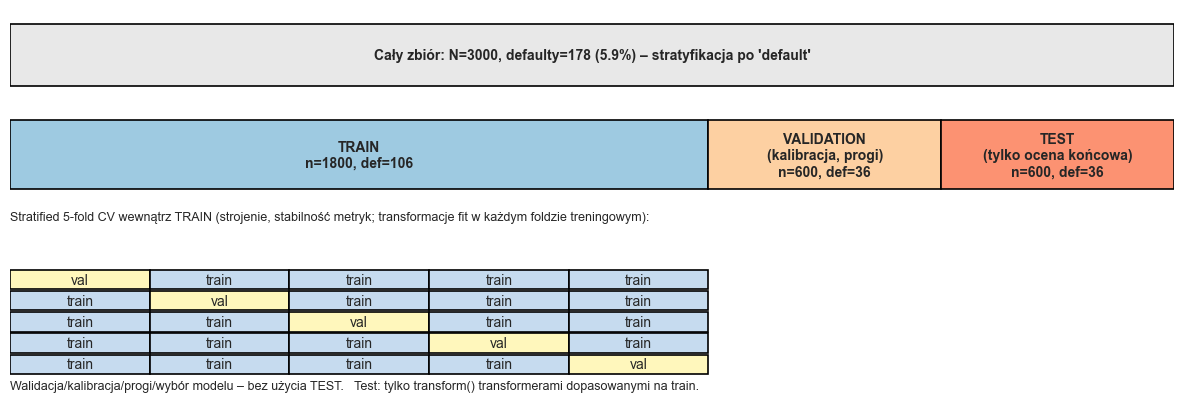

In [7]:
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(12, 4.2)); ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 10)
def box(x, w, y, h, txt, fc, bold=False):
    ax.add_patch(Rectangle((x, y), w, h, fc=fc, ec="black", lw=1.2))
    ax.text(x + w/2, y + h/2, txt, ha="center", va="center", fontsize=10, fontweight="bold" if bold else None)
n = len(df); w = lambda k: 100 * k / n
box(0, 100, 8, 1.6, f"Cały zbiór: N={n}, defaulty={y_all.sum()} ({y_all.mean():.1%}) – stratyfikacja po 'default'" + (" + grupy" if GROUPS is not None else ""), "#e8e8e8", True)
x0 = 0
for name, idx, col in [("TRAIN", idx_train, "#9ecae1"), ("VALIDATION\n(kalibracja, progi)", idx_val, "#fdd0a2"), ("TEST\n(tylko ocena końcowa)", idx_test, "#fc9272")]:
    box(x0, w(len(idx)), 5.3, 1.8, f"{name}\nn={len(idx)}, def={int(y_all[idx].sum())}", col, True); x0 += w(len(idx))
ax.text(0, 4.5, "Stratified 5-fold CV wewnątrz TRAIN (strojenie, stabilność metryk; transformacje fit w każdym foldzie treningowym):", fontsize=9)
fw = w(len(idx_train)) / N_FOLDS
for k in range(N_FOLDS):
    for j in range(N_FOLDS):
        box(j*fw, fw, 2.7 - k*0.55, 0.5, "val" if j == k else "train", "#fff7bc" if j == k else "#c6dbef")
ax.text(0, 0.1, "Walidacja/kalibracja/progi/wybór modelu – bez użycia TEST.   Test: tylko transform() transformerami dopasowanymi na train.", fontsize=9)
plt.tight_layout(); plt.savefig("figures/validation_scheme.png", dpi=150); plt.show()

## 3. Kontrola data leakage (3.1)

Sprawdzamy: (1) rozłączność zbiorów, (2) brak wspólnych podmiotów / identycznych obserwacji między zbiorami, (3) czy któraś zmienna nie jest „zbyt dobra" (podejrzenie, że zawiera informację o przyszłości / o samym defaulcie), (4) przepływ transformacji.

In [8]:
# 3.1 rozłączność i pokrycie
sets = {"train": set(idx_train), "val": set(idx_val), "test": set(idx_test)}
assert sets["train"].isdisjoint(sets["val"]) and sets["train"].isdisjoint(sets["test"]) and sets["val"].isdisjoint(sets["test"])
assert len(sets["train"] | sets["val"] | sets["test"]) == len(df)
for tr, va in cv_train + cv_dev:
    assert set(tr).isdisjoint(va)
assert set(i for _, va in cv_train for i in va) == sets["train"]       # każdy rekord train jest raz w walidacji CV
assert sets["test"].isdisjoint(set(i for tr, va in cv_dev for i in np.r_[tr, va]) & sets["test"])
print("OK: zbiory rozłączne, CV poprawne, test nie występuje w żadnym foldzie.")

# 3.2 identyczne obserwacje / podmioty między zbiorami
row_hash = pd.util.hash_pandas_object(df_raw.drop(columns=[TARGET]), index=False)
for a, b in [("train", "test"), ("train", "val"), ("val", "test")]:
    ha, hb = set(row_hash.iloc[list(sets[a])]), set(row_hash.iloc[list(sets[b])])
    fa, fb = set(fp.iloc[list(sets[a])]), set(fp.iloc[list(sets[b])])
    print(f"{a}-{b}: wspólne identyczne wiersze = {len(ha & hb)}, wspólne 'odciski' firm = {len(fa & fb)}")

OK: zbiory rozłączne, CV poprawne, test nie występuje w żadnym foldzie.
train-test: wspólne identyczne wiersze = 0, wspólne 'odciski' firm = 0
train-val: wspólne identyczne wiersze = 0, wspólne 'odciski' firm = 0
val-test: wspólne identyczne wiersze = 0, wspólne 'odciski' firm = 0


### 3.3 Podejrzane zmienne – siła jednowymiarowa (tylko train)

Zmienne o bardzo wysokim AUC jednowymiarowym lub IV (> 0,5 to klasycznie „zbyt dobre", żeby być prawdziwe) mogą zawierać informację zależną od defaultu (np. wyliczoną po jego wystąpieniu). Zmienne **spoza opisu** (`wsk_index_*`) wymagają szczególnej uwagi.

In [9]:
Xtr_raw, ytr = df.iloc[idx_train], y_all[idx_train]

def univ_auc(s, y):
    s = s.replace([np.inf, -np.inf], np.nan); m = s.notna()
    return roc_auc_score(y[m], s[m]) if m.sum() > 20 and s[m].nunique() > 1 and y[m].min() != y[m].max() else np.nan

num_for_scan = [c for c in NUM_BLACK if c in Xtr_raw.columns]
uni = pd.DataFrame({
    "AUC": {c: univ_auc(Xtr_raw[c], ytr) for c in num_for_scan},
    "brak_%": {c: Xtr_raw[c].replace([np.inf, -np.inf], np.nan).isna().mean() * 100 for c in num_for_scan}})
uni["sila_|AUC-0.5|"] = (uni["AUC"] - 0.5).abs()
uni["opisana_w_slowniku"] = [c not in UNDESCRIBED for c in uni.index]
uni = uni.sort_values("sila_|AUC-0.5|", ascending=False)
display(uni.head(15))
print("Zmienne spoza opisu:"); display(uni.loc[[c for c in UNDESCRIBED if c in uni.index]])

,AUC,brak_%,sila_|AUC-0.5|,opisana_w_slowniku
wsk_index_skr_zaw,0.7034,0.0000,0.2034,False
wsk_index_nowe,0.7011,0.0000,0.2011,False
slog_Kapital_wlasny,0.3213,0.0000,0.1787,True
wsk_poziom_kapitalu_obrotowego_netto,0.3546,0.0000,0.1454,True
slog_zysk_netto,0.3611,0.0000,0.1389,True
slog_zysk_brutto,0.3616,0.0000,0.1384,True
slog_Zysk_netto,0.3622,0.0000,0.1378,True
wsk_rent_kaptial_podstawowy,0.3665,0.0000,0.1335,True
wsk_ebit,0.3695,0.0000,0.1305,True
wsk_ebitda_1,0.3763,0.0000,0.1237,True


Zmienne spoza opisu:


,AUC,brak_%,sila_|AUC-0.5|,opisana_w_slowniku
wsk_index_aktywne,0.5759,0.0000,0.0759,False
wsk_index_skr_zaw,0.7034,0.0000,0.2034,False
wsk_index_nowe,0.7011,0.0000,0.2011,False


> **⚠ Do ręcznej weryfikacji.** Jeśli `wsk_index_nowe` / `wsk_index_skr_zaw` mają wysoki AUC/IV, a nie ma ich w opisie zmiennych, ustal (z prowadzącym lub w dokumentacji zbioru), co oznaczają i czy są dostępne w momencie oceny ryzyka. Jeśli nie – usuń je: ustaw `DROP_SUSPICIOUS = True` poniżej. Decyzję opisz w raporcie (sekcja Walidacja i leakage) i w `MODEL_CARD.md`.

In [10]:
DROP_SUSPICIOUS = False                      # <- ustaw True, jeśli zmienne okażą się niedozwolone (leakage)
SUSPICIOUS = ["wsk_index_aktywne", "wsk_index_skr_zaw", "wsk_index_nowe"]
if DROP_SUSPICIOUS:
    NUM_INTERP = [c for c in NUM_INTERP if c not in SUSPICIOUS]
    NUM_BLACK  = [c for c in NUM_BLACK  if c not in SUSPICIOUS]
print("Usunięte podejrzane zmienne:", DROP_SUSPICIOUS, "| liczba cech interp./black-box:", len(NUM_INTERP), len(NUM_BLACK))

Usunięte podejrzane zmienne: False | liczba cech interp./black-box: 140 218


### 3.4 Przepływ transformacji (dlaczego nie ma leakage)

| Krok | Gdzie wykonywany | Uczy się z danych? |
|---|---|---|
| `inf → NaN`, `log_aktywa`, `signed_log1p`, agregacja PKD do działu | przed podziałem | nie (reguły wiersz-po-wierszu) |
| Odrzucenie cech rzadkich/quasi-stałych, kwantyle winsoryzacji, mediany, średnie/odch. | `.fit()` na train / foldzie train | tak |
| Grupowanie rzadkich kategorii (próg liczebności) | `.fit()` na train / foldzie train | tak |
| Binning monotoniczny, WoE, IV, selekcja po IV i korelacji | `.fit()` na train / foldzie train (wymaga `y`) | tak |
| Walidacja / test | tylko `.transform()` | nie |

Ponieważ selekcja cech i WoE używają `y`, w CV są powtarzane **w każdym foldzie osobno** (patrz sekcja 7) – to najczęstsze źródło ukrytego leakage.

## 4. Jakość danych – Data Quality (3.2)

Kontrola na zbiorze treningowym (decyzje o usuwaniu cech podejmowane są później automatycznie w `fit()` na train/foldach).

In [11]:
Xtr = Xtr_raw[RATIO_COLS + LEVEL_COLS].copy()
inf_cnt = np.isinf(Xtr).sum(); Xtr = Xtr.replace([np.inf, -np.inf], np.nan)

dq = pd.DataFrame({
    "braki_%": Xtr.isna().mean() * 100,
    "inf_szt": inf_cnt,
    "zera_%": (Xtr == 0).mean() * 100,
    "unikalne": Xtr.nunique(),
    "min": Xtr.min(), "p01": Xtr.quantile(.01), "mediana": Xtr.median(), "p99": Xtr.quantile(.99), "max": Xtr.max(),
    "skosnosc": Xtr.skew()})
print("Kolumny z brakami / inf:"); display(dq[(dq["braki_%"] > 0) | (dq["inf_szt"] > 0)].sort_values("braki_%", ascending=False))
print(f"Cechy >=99% zer lub >=99% jednej wartości (kandydaci do usunięcia): "
      f"{(dq['zera_%'] >= 99).sum()}; stałe: {(dq['unikalne'] <= 1).sum()}")
display(dq[dq["zera_%"] >= 99].index.tolist())

Kolumny z brakami / inf:


,braki_%,inf_szt,zera_%,unikalne,min,p01,mediana,p99,max,skosnosc
wsk_akt_generowania_got_2,98.8889,0,0.5000,12,-0.4868,-0.4280,0.0000,0.3329,0.3392,-0.8447
wsk_pokrycie_wyd_fin_gotowkowe_2,98.8889,0,0.5000,12,-635.3717,-555.8482,0.0000,"2,397.1803","2,562.9098",2.6001
RP_przeplywy_operacyjne,98.8889,0,0.5000,12,"-5,390,296.5000","-5,149,512.7737",0.0000,"55,542,822.0474","67,128,118.3200",4.2937
wsk_pokrycie_zob_kr_gotowkowe_2,98.8889,0,0.5000,12,-60.4531,-49.5927,0.0000,9.1353,10.4402,-4.2017
wsk_zadluzenia_gotowki_2,98.8889,0,0.4444,13,-0.9882,-0.8005,0.0261,"64,935.4332","65,348.1332",1.7615
wsk_zysk_CF_operacyjny,98.8889,0,0.0000,20,"-1,392.1954","-1,244.1396",0.3412,"223,216.9767","271,903.3272",4.4417
RP_amortyzacja,95.8889,0,0.9444,58,0.0000,0.0000,"230,110.0400","7,891,228.5912","12,099,412.5500",3.4265
wsk_plynnosc_biez_1,32.2778,521,0.1667,1217,-81.2847,0.0183,2.2674,396.0217,"50,079.6941",33.8643
wsk_struktura_kap_wlasnego_s_2,4.7222,59,1.4444,1618,-149.1010,0.0000,0.7478,50.5218,"2,845,076,702,982,308.0000",41.4126
wsk_kapital_do_aktywa,1.7222,5,1.5000,1595,-0.0713,0.0000,0.6336,1.0000,10.1750,8.1059


Cechy >=99% zer lub >=99% jednej wartości (kandydaci do usunięcia): 9; stałe: 0


['Wartosc_firmy',
 'Naleznosci_dostaw_uslug_pow12m_powiazane',
 'Naleznosci_dostaw_uslug_pow12m_kapitale',
 'Pozostale_rezerwy',
 'Zobowiazania_dostaw_uslug_pow12m_powiazane',
 'Zobowiazania_dostaw_uslug_12m_kapitale',
 'Zobowiazania_dostaw_uslug_pow12m_kapitale',
 'Ujemna_wartosc_firmy',
 'Zobowiazania_dostaw_uslug_pow12m']

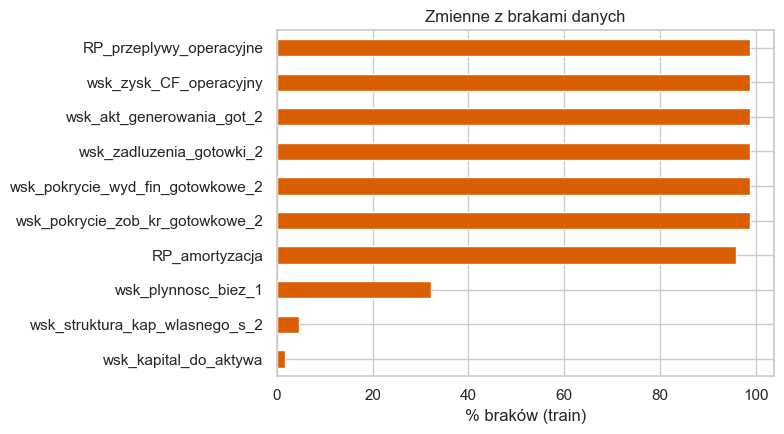

Niespójność Aktywa vs trwałe+obrotowe  (>1% aktywów): 53 obs.
Niespójność Aktywa vs Kap.własny+Zob.i rezerwy (>1%): 59 obs.
Ujemne wartości w pozycjach nieujemnych:


Aktywa                                     1
Aktywa_trwale                              2
Srodki_trwale                              1
Aktywa_obrotowe                            1
Srodki_pieniezne                           1
Kapital_podstawowy                         1
Zobowiazania_rezerwy                       3
Zobowiazania_dlugoterminowe                1
Kredyty_pozyczki_dlugie                    1
Zobowiazania_krotkoterminowe               1
Kredyty_pozyczki_krotkie                   1
Zobowiazania_dostaw_uslug_12m_pozostale    2
Naleznosci_dostaw_uslug_pow12m             1
przychody_sprzedazy                        5
przychody_finansowe                        2
przychody                                  1
dtype: int64

Aktywa <= 0: 32 | Kapitał własny < 0: 1 | wiek firmy <= 0 dni: 0


In [12]:
# 4.1 braki - wizualizacja
miss = dq["braki_%"][dq["braki_%"] > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, 0.35 * len(miss) + 1)); miss.plot.barh(ax=ax, color="#d95f02")
ax.set_xlabel("% braków (train)"); ax.set_title("Zmienne z brakami danych"); plt.tight_layout(); plt.savefig("figures/missing.png", dpi=150); plt.show()

# 4.2 spójność księgowa (anomalie): Aktywa = Aktywa_trwale + Aktywa_obrotowe, Aktywa = Kapitał własny + Zobowiązania i rezerwy
t = Xtr_raw
a = t["Aktywa"].replace(0, np.nan)
gap1 = ((t["Aktywa"] - t["Aktywa_trwale"] - t["Aktywa_obrotowe"]).abs() / a.abs())
gap2 = ((t["Aktywa"] - t["Kapital_wlasny"] - t["Zobowiazania_rezerwy"]).abs() / a.abs())
print("Niespójność Aktywa vs trwałe+obrotowe  (>1% aktywów):", int((gap1 > .01).sum()), "obs.")
print("Niespójność Aktywa vs Kap.własny+Zob.i rezerwy (>1%):", int((gap2 > .01).sum()), "obs.")

# 4.3 wartości niemożliwe ekonomicznie
nonneg = [c for c in LEVEL_COLS if c.startswith(("Aktywa", "Zapasy", "Srodki_", "Zobowiazania", "Kredyty", "Naleznosci", "Kapital_podstawowy", "przychody"))]
neg = (t[nonneg] < 0).sum(); print("Ujemne wartości w pozycjach nieujemnych:"); display(neg[neg > 0])
print("Aktywa <= 0:", int((t["Aktywa"] <= 0).sum()), "| Kapitał własny < 0:", int((t["Kapital_wlasny"] < 0).sum()),
      "| wiek firmy <= 0 dni:", int((t["wsk_liczba_dni_istnienia"] <= 0).sum()))

Liczba obserwacji z co najmniej jednym brakiem (w train): 1781 (98.9%)


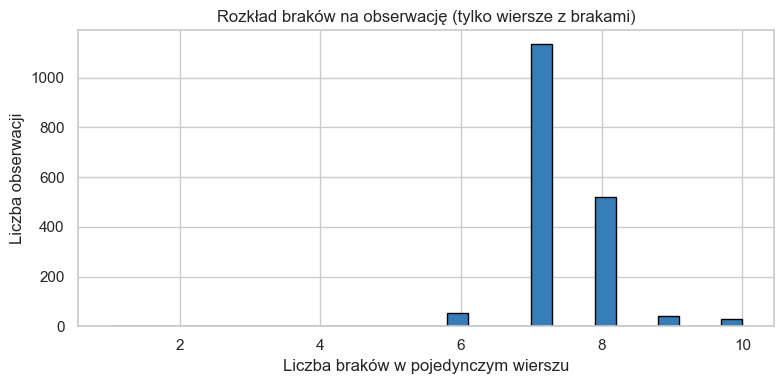

In [31]:
# Analiza braków na obserwację (wiersz)
braki_w_wierszu = Xtr.isna().sum(axis=1)
obserwacje_z_brakami = (braki_w_wierszu > 0).sum()
procent_z_brakami = obserwacje_z_brakami / len(Xtr) * 100

print(f"Liczba obserwacji z co najmniej jednym brakiem (w train): {obserwacje_z_brakami} ({procent_z_brakami:.1f}%)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(braki_w_wierszu[braki_w_wierszu > 0], bins=30, edgecolor="black", color="#377eb8")
ax.set_xlabel("Liczba braków w pojedynczym wierszu")
ax.set_ylabel("Liczba obserwacji")
ax.set_title("Rozkład braków na obserwację (tylko wiersze z brakami)")
plt.tight_layout()
plt.show()

In [13]:
# 4.4 obserwacje odstające: ekstremalne wartości względem rozkładu (kandydaci do cappingu)
rng = (Xtr.quantile(.99) - Xtr.quantile(.01)).replace(0, np.nan)
ext = pd.DataFrame({"max/zakres_p01-p99": (Xtr.max() - Xtr.quantile(.99)) / rng,
                    "min/zakres_p01-p99": (Xtr.quantile(.01) - Xtr.min()) / rng}).max(axis=1).sort_values(ascending=False)
print("Cechy z najbardziej ekstremalnymi ogonami (ile 'zakresów p1–p99' poza p99/p1):"); display(ext.head(10).to_frame("miara"))
print("\nPOLITYKA: winsoryzacja do [p1, p99] liczona na train (model black-box); w modelu WoE ekstrema są odporne dzięki binningowi kwantylowemu.")

# 4.5 kategorie
for c in ["formaWlasnosci_Symbol", "schemat_wsk_bilans", "schemat_wsk_rzis"]:
    print(f"\n{c}: poziomy={Xtr_raw[c].nunique()}"); display(Xtr_raw[c].value_counts().head(8).to_frame("n").T)
print("szczegolnaFormaPrawna_Symbol – liczba poziomów:", Xtr_raw["szczegolnaFormaPrawna_Symbol"].nunique(), "(stała → zostanie usunięta)")
print("pkdKod: poziomów =", Xtr_raw["pkdKod"].nunique(), "→ po agregacji do działu (pkd_div):", Xtr_raw["pkd_div"].nunique())

Cechy z najbardziej ekstremalnymi ogonami (ile 'zakresów p1–p99' poza p99/p1):


,miara
wsk_struktura_kap_wlasnego_s_2,"56,313,846,025,406.0000"
wsk_rotacja_aktywow_1,"4,167,649,970,455.2944"
wsk_pokrycia_zobowiazan_rz_aktywami_trwalymi,"137,493,216,486.9448"
wsk_zadluzenie_gotowka,"9,213.1074"
wsk_koszty_odsetki_przychody,"9,213.1074"
wsk_ebitda_zobowiazan_odsetki_2,"9,155.2045"
wsk_ebitda_koszty_odsetkowe_2,"9,155.2045"
wsk_pokrycia_odsetek_zyskiem,"5,769.1791"
wsk_ebitda_zobowiazan_odsetki_1,"4,602.8840"
wsk_ebitda_koszty_odsetkowe_1,"4,602.8840"



POLITYKA: winsoryzacja do [p1, p99] liczona na train (model black-box); w modelu WoE ekstrema są odporne dzięki binningowi kwantylowemu.

formaWlasnosci_Symbol: poziomy=18


formaWlasnosci_Symbol,214,215,216,0,224,226,225,113
n,1217,164,151,96,46,36,36,19



schemat_wsk_bilans: poziomy=3


schemat_wsk_bilans,SFJIN,SFJMI,SFJMA
n,952,467,381



schemat_wsk_rzis: poziomy=3


schemat_wsk_rzis,SFJIN,SFJMI,SFJMA
n,978,458,364


szczegolnaFormaPrawna_Symbol – liczba poziomów: 1 (stała → zostanie usunięta)
pkdKod: poziomów = 328 → po agregacji do działu (pkd_div): 74


**Podsumowanie polityki Data Quality (realizowane automatycznie w `FinancialCleaner` / `CategoryGrouper`, parametry z train):**

| Problem | Reguła |
|---|---|
| ±inf (dzielenie przez 0 we wskaźnikach) | → `NaN` |
| Cechy z >90% braków (bloki `RP_*` – rachunek przepływów) | usunięte |
| Cechy quasi-stałe (≥99% tej samej wartości, np. goodwill, pozycje „powiązane/kapitałowe") | usunięte |
| Braki w pozostałych cechach | black-box: mediana z train + wskaźnik braku (`__isna`) przy brakach ≥2%; WoE: brak = osobny bin |
| Ekstrema | black-box: winsoryzacja p1–p99 (kwantyle z train); WoE: binning kwantylowy |
| Rzadkie kategorie (<30 obs. w train) | → `RARE` |
| Stała forma prawna | usunięta |

## 5. EDA – wyłącznie na zbiorze treningowym (3.2)

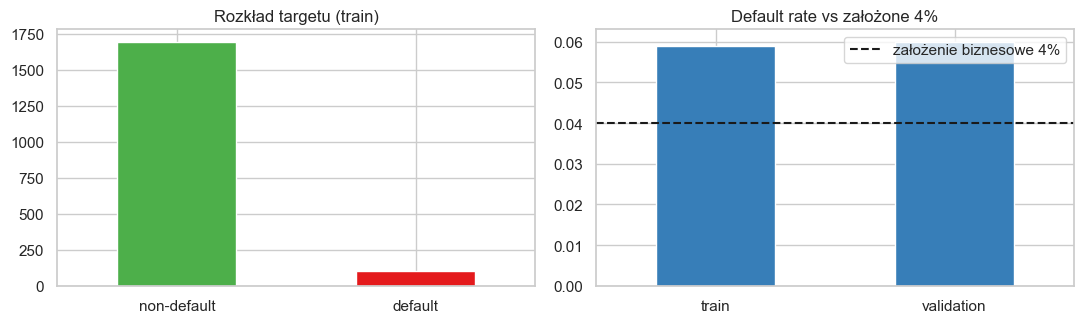

Default rate w train: 5.89% (założona tendencja centralna PD: 4%) – różnica będzie wymagała adresowania w kalibracji.


In [14]:
# 5.1 target
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
pd.Series(ytr).value_counts().sort_index().plot.bar(ax=ax[0], color=["#4daf4a", "#e41a1c"]); ax[0].set_title("Rozkład targetu (train)")
ax[0].set_xticklabels(["non-default", "default"], rotation=0)
rates = pd.Series({"train": y_all[idx_train].mean(), "validation": y_all[idx_val].mean()})   # test celowo pominięty w EDA
rates.plot.bar(ax=ax[1], color="#377eb8"); ax[1].axhline(0.04, color="k", ls="--", label="założenie biznesowe 4%"); ax[1].legend()
ax[1].set_title("Default rate vs założone 4%"); ax[1].set_xticklabels(rates.index, rotation=0); plt.tight_layout(); plt.show()
print(f"Default rate w train: {ytr.mean():.2%} (założona tendencja centralna PD: 4%) – różnica będzie wymagała adresowania w kalibracji.")

,AUC,Spearman z targetem
wsk_index_skr_zaw,0.7034,0.1659
wsk_index_nowe,0.7011,0.1640
slog_Kapital_wlasny,0.3213,-0.1457
wsk_poziom_kapitalu_obrotowego_netto,0.3546,-0.1186
slog_zysk_netto,0.3611,-0.1150
slog_zysk_brutto,0.3616,-0.1146
slog_Zysk_netto,0.3622,-0.1141
wsk_rent_kaptial_podstawowy,0.3665,-0.1105
wsk_ebit,0.3695,-0.1080
wsk_ebitda_1,0.3763,-0.1014


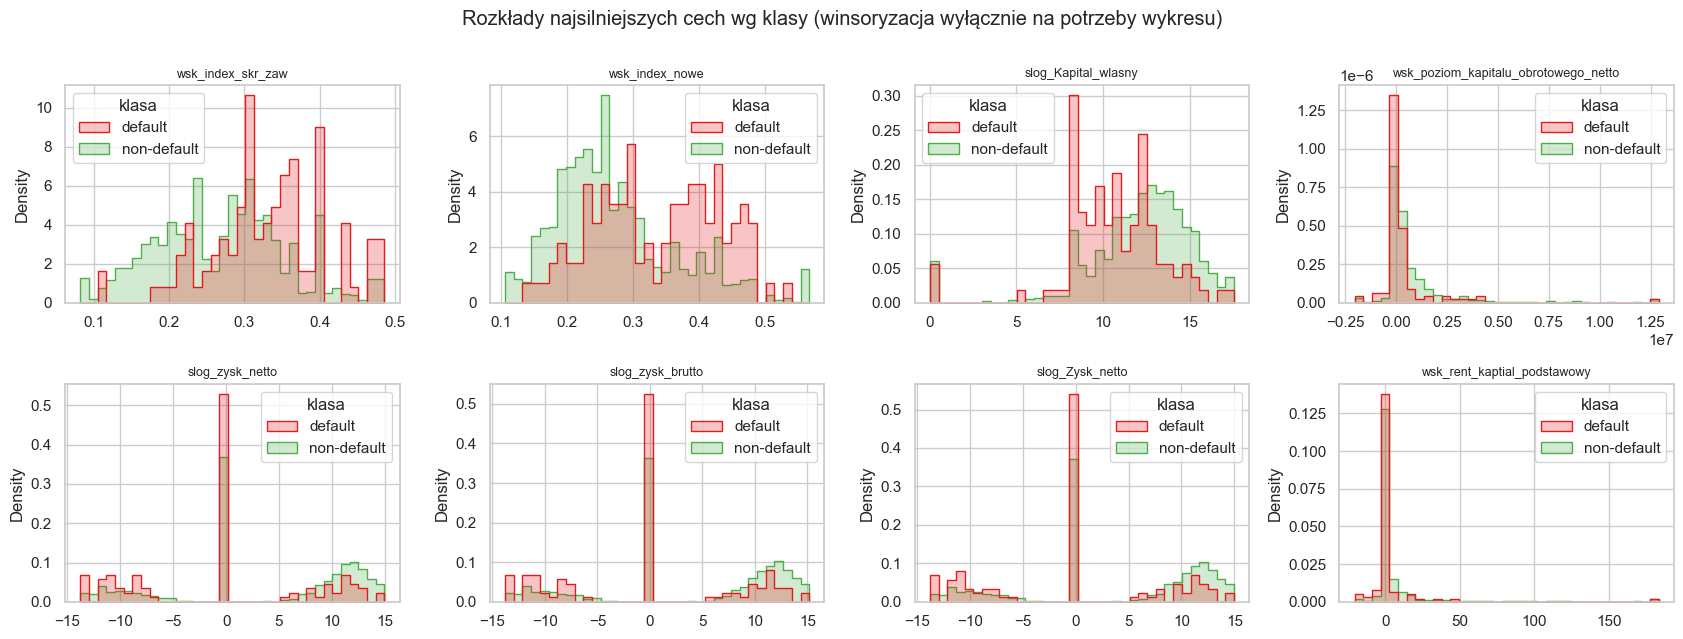

In [15]:
# 5.2 zależności z targetem: top cech jednowymiarowych (AUC / Spearman) + rozkłady wg klasy
top = uni.dropna(subset=["AUC"]).head(8).index.tolist()
sp = pd.Series({c: stats.spearmanr(Xtr_raw[c].replace([np.inf, -np.inf], np.nan), ytr, nan_policy="omit")[0] for c in uni.index[:30]})
display(pd.DataFrame({"AUC": uni.loc[sp.index, "AUC"], "Spearman z targetem": sp}).head(20))

fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for ax, c in zip(axes.ravel(), top):
    s = Xtr_raw[c].replace([np.inf, -np.inf], np.nan); lo, hi = s.quantile([.01, .99])
    plot_df = pd.DataFrame({"x": s.clip(lo, hi), "klasa": np.where(ytr == 1, "default", "non-default")}).dropna()
    sns.histplot(data=plot_df, x="x", hue="klasa", stat="density", common_norm=False, bins=35, element="step", ax=ax,
                 palette={"default": "#e41a1c", "non-default": "#4daf4a"})
    ax.set_title(c, fontsize=9); ax.set_xlabel("")
plt.suptitle("Rozkłady najsilniejszych cech wg klasy (winsoryzacja wyłącznie na potrzeby wykresu)"); plt.tight_layout(); plt.savefig("figures/eda_top_features.png", dpi=150); plt.show()

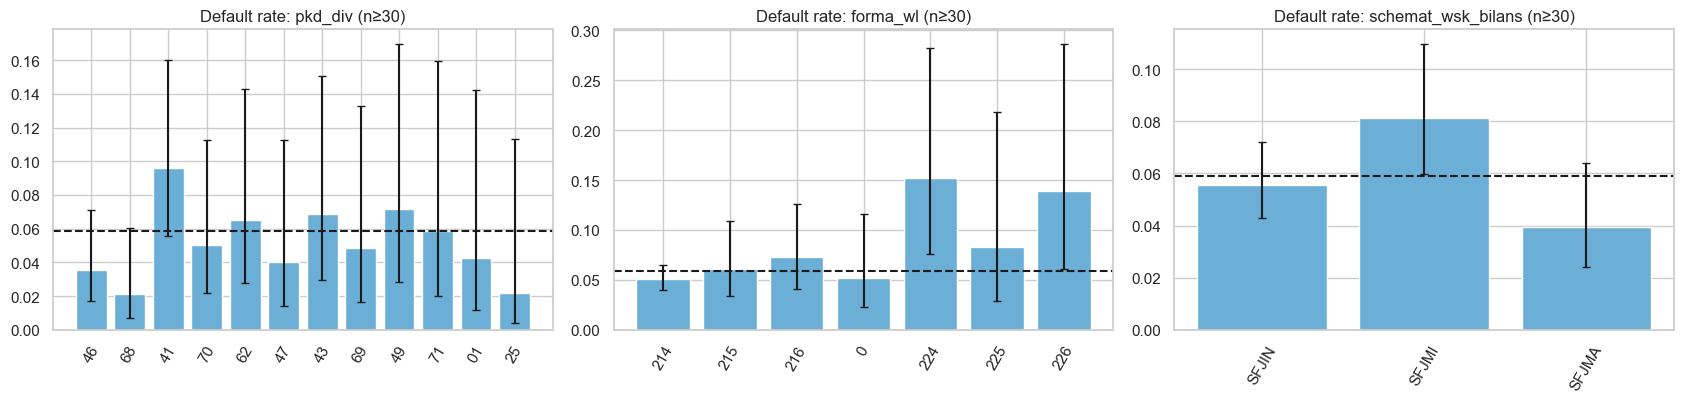

,n,defaulty,default_rate,ci_lo,ci_hi
pkd_div,,,,,
46,198,7,0.0354,0.0172,0.0712
68,141,3,0.0213,0.0073,0.0607
41,125,12,0.0960,0.0558,0.1603
70,99,5,0.0505,0.0218,0.1128
62,77,5,0.0649,0.0281,0.1432
47,74,3,0.0405,0.0139,0.1125
43,73,5,0.0685,0.0296,0.1505
69,62,3,0.0484,0.0166,0.1329
49,56,4,0.0714,0.0281,0.1698


In [16]:
# 5.3 default rate wg kategorii (z 95% przedziałem Wilsona)
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2*n)) / d; h = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    return c - h, c + h

def rate_table(col, min_n=30):
    g = Xtr_raw.assign(y=ytr).groupby(col)["y"].agg(["count", "sum"]).rename(columns={"count": "n", "sum": "defaulty"})
    g = g[g["n"] >= min_n].copy(); g["default_rate"] = g["defaulty"] / g["n"]
    g["ci_lo"], g["ci_hi"] = zip(*[wilson(k, n) for k, n in zip(g["defaulty"], g["n"])]); return g.sort_values("n", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, c in zip(axes, ["pkd_div", "forma_wl", "schemat_wsk_bilans"]):
    g = rate_table(c).head(12)
    ax.bar(g.index.astype(str), g["default_rate"], yerr=[g["default_rate"] - g["ci_lo"], g["ci_hi"] - g["default_rate"]], capsize=3, color="#6baed6")
    ax.axhline(ytr.mean(), color="k", ls="--"); ax.set_title(f"Default rate: {c} (n≥30)"); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
display(rate_table("pkd_div").head(10))

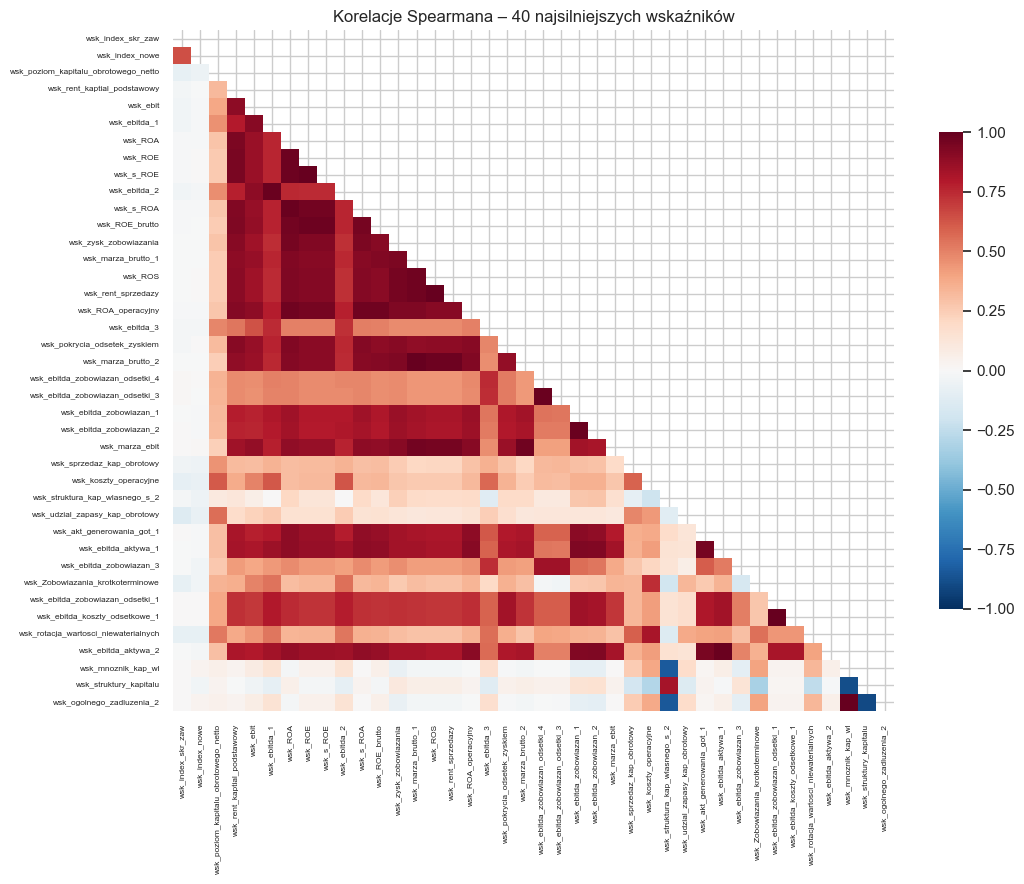

Par o |ρ| > 0.9: 201 z 8778 -> silna redundancja (wiele wskaźników to warianty tej samej miary).


rho
wsk_kapital_do_aktywa            wsk_udzial_kap_wlasnego_aktywa_1 1.0000
                                 wsk_struktura_kap_wlasnego_1     1.0000
wsk_ROS                          wsk_rent_sprzedazy               1.0000
wsk_ebitda_koszty_odsetkowe_1    wsk_ebitda_zobowiazan_odsetki_1  1.0000
wsk_ebitda_koszty_odsetkowe_2    wsk_ebitda_zobowiazan_odsetki_2  1.0000
wsk_koszty_odsetki_przychody     wsk_zadluzenie_gotowka           1.0000
wsk_zysk_op_zobowiazania         wsk_zysk_operacyjny_zob_1        1.0000
wsk_koszty_fin_przychody         wsk_poziom_kosztow_finansowych   1.0000
wsk_koszty_przychody             wsk_poziom_kosztow_operacyjnych  1.0000
wsk_udzial_kap_wlasnego_aktywa_1 wsk_struktura_kap_wlasnego_1     1.0000

In [26]:
# 5.4 korelacje (Spearman, odporna na ogony): top cechy + pary silnie skorelowane
base = Xtr_raw[RATIO_COLS].replace([np.inf, -np.inf], np.nan)
base = base.loc[:, base.notna().mean() > .9]
corr = base.corr(method="spearman")
top40 = uni.loc[[c for c in uni.index if c in corr.columns]].head(40).index
fig, ax = plt.subplots(figsize=(11, 9)); mask = np.triu(np.ones((40, 40), bool))
sns.heatmap(corr.loc[top40, top40], mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .7},
            xticklabels=True, yticklabels=True); ax.tick_params(labelsize=6)
ax.set_title("Korelacje Spearmana – 40 najsilniejszych wskaźników"); plt.tight_layout(); plt.savefig("figures/corr_top40.png", dpi=150); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print(f"Par o |ρ| > 0.9: {(pairs.abs() > .9).sum()} z {len(pairs)} -> silna redundancja (wiele wskaźników to warianty tej samej miary).")
display(pairs[pairs.abs() > .9].sort_values(key=abs, ascending=False).head(10).to_frame("rho"))

In [27]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Przygotowanie danych (usunięcie nieskończoności i imputacja medianą)
X_vif = Xtr_raw[NUM_INTERP].replace([np.inf, -np.inf], np.nan)
cols_to_keep = X_vif.columns[X_vif.isna().mean() < 0.1]
X_vif = X_vif[cols_to_keep].fillna(X_vif[cols_to_keep].median())

# 2. Usunięcie cech stałych (wariancja = 0)
X_vif = X_vif.loc[:, X_vif.nunique() > 1]

# 3. Zabezpieczenie przed SingularMatrixWarning: 
# Usunięcie jednej cechy z każdej pary o korelacji > 0.95 (idealna współliniowość)
corr_matrix = X_vif.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
X_vif = X_vif.drop(columns=to_drop)

# 4. Obliczenie VIF na oczyszczonym zbiorze
vif_data = pd.DataFrame()
vif_data["cecha"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(X_vif.columns))]

print(f"Obliczono VIF dla {len(X_vif.columns)} cech (odrzucono {len(to_drop)} skrajnie skorelowanych).")
print("Kandydaci do usunięcia (zazwyczaj odrzuca się cechy z VIF > 5 lub 10):")
display(vif_data.sort_values("VIF", ascending=False).head(15))

Obliczono VIF dla 88 cech (odrzucono 46 skrajnie skorelowanych).
Kandydaci do usunięcia (zazwyczaj odrzuca się cechy z VIF > 5 lub 10):


,cecha,VIF
14,wsk_s_ROA,"160,521.3555"
39,wsk_udzial_kap_wlasnego_aktywa_2,"123,796.6436"
13,wsk_ROA,"55,276.4978"
46,wsk_ROA_operacyjny,"20,823.0482"
20,wsk_akt_generowania_got_1,"19,936.8275"
33,wsk_struktury_finansowania,"9,386.9190"
86,wsk_zob_s_aktywa_rzeczowe,"3,204.3675"
70,wsk_udzial_zob_biez_aktywa_2,"2,551.9872"
53,wsk_ebitda_zobowiazan_3,"1,688.2163"
35,wsk_zysk_operacyjny_zob_2,"1,361.6209"


Analiza podgrup: Default rate wg wielkości firmy (Aktywa)


,liczba_obserwacji,default_rate
Aktywa_Grupa,,
Małe,450,0.0867
Średnie-Niższe,450,0.0667
Średnie-Wyższe,450,0.0467
Duże,450,0.0356


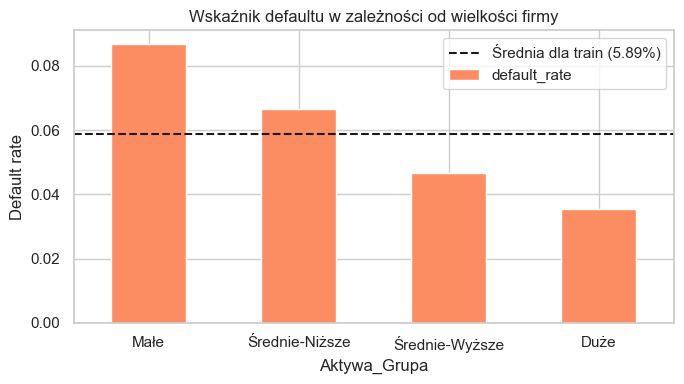

In [28]:
# Analiza stabilności ryzyka w podgrupach (wielkość firmy po Aktywach)
X_subgroups = Xtr_raw.copy()
# Podział na 4 kwantyle (koszyki) wielkości aktywów
X_subgroups['Aktywa_Grupa'] = pd.qcut(X_subgroups['Aktywa'], q=4, labels=['Małe', 'Średnie-Niższe', 'Średnie-Wyższe', 'Duże'])

grupy_aktywa = X_subgroups.assign(y=ytr).groupby('Aktywa_Grupa')['y'].agg(['count', 'mean']).rename(columns={'count': 'liczba_obserwacji', 'mean': 'default_rate'})

print("Analiza podgrup: Default rate wg wielkości firmy (Aktywa)")
display(grupy_aktywa)

fig, ax = plt.subplots(figsize=(7, 4))
grupy_aktywa['default_rate'].plot.bar(ax=ax, color="#fc8d62")
ax.axhline(ytr.mean(), color="k", ls="--", label=f"Średnia dla train ({ytr.mean():.2%})")
ax.set_title("Wskaźnik defaultu w zależności od wielkości firmy")
ax.set_ylabel("Default rate")
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Wnioski z EDA do opisania w raporcie** (uzupełnij po obejrzeniu wyników): które cechy najsilniej różnicują default (zadłużenie, rentowność kapitału, płynność, wiek firmy…) i czy kierunek zgadza się z intuicją ekonomiczną; skala redundancji między wskaźnikami (uzasadnienie selekcji po korelacji i kontroli VIF w modelu interpretowalnym); różnice default rate między PKD / formami własności (i ich wiarygodność – szerokie przedziały przy małych n).

## 6. Przygotowanie cech (3.2)

Dwie ścieżki zbudowane na tym samym API `ScoringFeatureBuilder(mode=...)`:

| | `mode="woe"` (model interpretowalny) | `mode="blackbox"` |
|---|---|---|
| Czyszczenie | inf→NaN, usunięcie cech rzadkich / quasi-stałych | to samo + winsoryzacja p1–p99 |
| Braki | osobny bin „BRAK" | imputacja medianą + wskaźniki braków |
| Cechy | **binning monotoniczny + WoE** (max 8 binów, ≥5% obs. w binie), kategorie → WoE | wskaźniki + `slog_*` pozycji kwotowych + one-hot kategorii |
| Selekcja | IV ≥ 0,02, a z pary silnie skorelowanej (\|r\| ≥ 0,8) zostaje cecha o wyższym IV | brak (selekcję robi model; opcjonalnie `scale=True` dla SVM/sieci) |

Konwencja WoE: **WoE = ln(%bad / %good)** → WoE > 0 = wyższe ryzyko, więc oczekiwany znak współczynnika regresji logistycznej jest dodatni.

In [19]:
FB_PARAMS_WOE = dict(num_cols=NUM_INTERP, cat_cols=CAT_COLS, mode="woe",
                     max_bins=8, min_bin_frac=0.05, iv_min=0.02, corr_max=0.80, min_cat=30)
FB_PARAMS_BB  = dict(num_cols=NUM_BLACK,  cat_cols=CAT_COLS, mode="blackbox",
                     winsor=(0.01, 0.99), min_cat=30, scale=False)

# dopasowanie na CAŁYM zbiorze treningowym (do dalszych notebooków); w CV fit powtarzany w każdym foldzie
fb_woe = ScoringFeatureBuilder(**FB_PARAMS_WOE).fit(df.iloc[idx_train], y_all[idx_train])
fb_bb  = ScoringFeatureBuilder(**FB_PARAMS_BB ).fit(df.iloc[idx_train], y_all[idx_train])

print("Usunięte (za dużo braków):", fb_bb.cleaner_.dropped_["za_duzo_brakow"])
print("Usunięte (quasi-stałe):   ", fb_bb.cleaner_.dropped_["quasi_stale"][:8], "...")
print(f"Cechy po transformacji: WoE = {len(fb_woe.feature_names_)}, black-box = {len(fb_bb.feature_names_)}")
iv = fb_woe.iv_table_
display(iv[iv["status"] == "wybrana"].head(20))
print("Statusy cech:", iv["status"].value_counts().to_dict())
print("Cechy wybrane z niemonotoniczną relacją WoE (powinno być 0):", int((iv[iv.status == 'wybrana']['monotoniczna'] == False).sum()))
print("Cechy z IV > 0.5 (podejrzanie silne – zweryfikuj):", iv[iv["IV"] > 0.5].index.tolist())

Usunięte (za dużo braków): ['wsk_akt_generowania_got_2', 'wsk_pokrycie_wyd_fin_gotowkowe_2', 'wsk_pokrycie_zob_kr_gotowkowe_2', 'wsk_zadluzenia_gotowki_2', 'wsk_zysk_CF_operacyjny', 'slog_RP_przeplywy_operacyjne', 'slog_RP_amortyzacja']
Usunięte (quasi-stałe):    ['slog_Wartosc_firmy', 'slog_Naleznosci_dostaw_uslug_pow12m_powiazane', 'slog_Naleznosci_dostaw_uslug_pow12m_kapitale', 'slog_Pozostale_rezerwy', 'slog_Zobowiazania_dostaw_uslug_pow12m_powiazane', 'slog_Zobowiazania_dostaw_uslug_12m_kapitale', 'slog_Zobowiazania_dostaw_uslug_pow12m_kapitale', 'slog_Ujemna_wartosc_firmy'] ...
Cechy po transformacji: WoE = 68, black-box = 237


,IV,n_bins,monotoniczna,kierunek,status
wsk_index_skr_zaw,0.6232,6,True,inc,wybrana
wsk_index_nowe,0.5126,8,True,inc,wybrana
wsk_mnoznik_kap_wl,0.3275,5,True,inc,wybrana
wsk_poziom_kapitalu_obrotowego_netto,0.3073,8,True,dec,wybrana
wsk_ebitda_1,0.3068,8,True,dec,wybrana
wsk_ROE,0.2941,3,True,dec,wybrana
wsk_rent_kaptial_podstawowy,0.2757,6,True,dec,wybrana
wsk_ebitda_3,0.2249,5,True,dec,wybrana
wsk_efekt_dzwigni_fin_1,0.2166,3,True,inc,wybrana
wsk_plynnosc_biez_1,0.2153,4,True,dec,wybrana


Statusy cech: {'korelacja / limit cech': 71, 'wybrana': 68}
Cechy wybrane z niemonotoniczną relacją WoE (powinno być 0): 0
Cechy z IV > 0.5 (podejrzanie silne – zweryfikuj): ['wsk_index_skr_zaw', 'wsk_index_nowe']


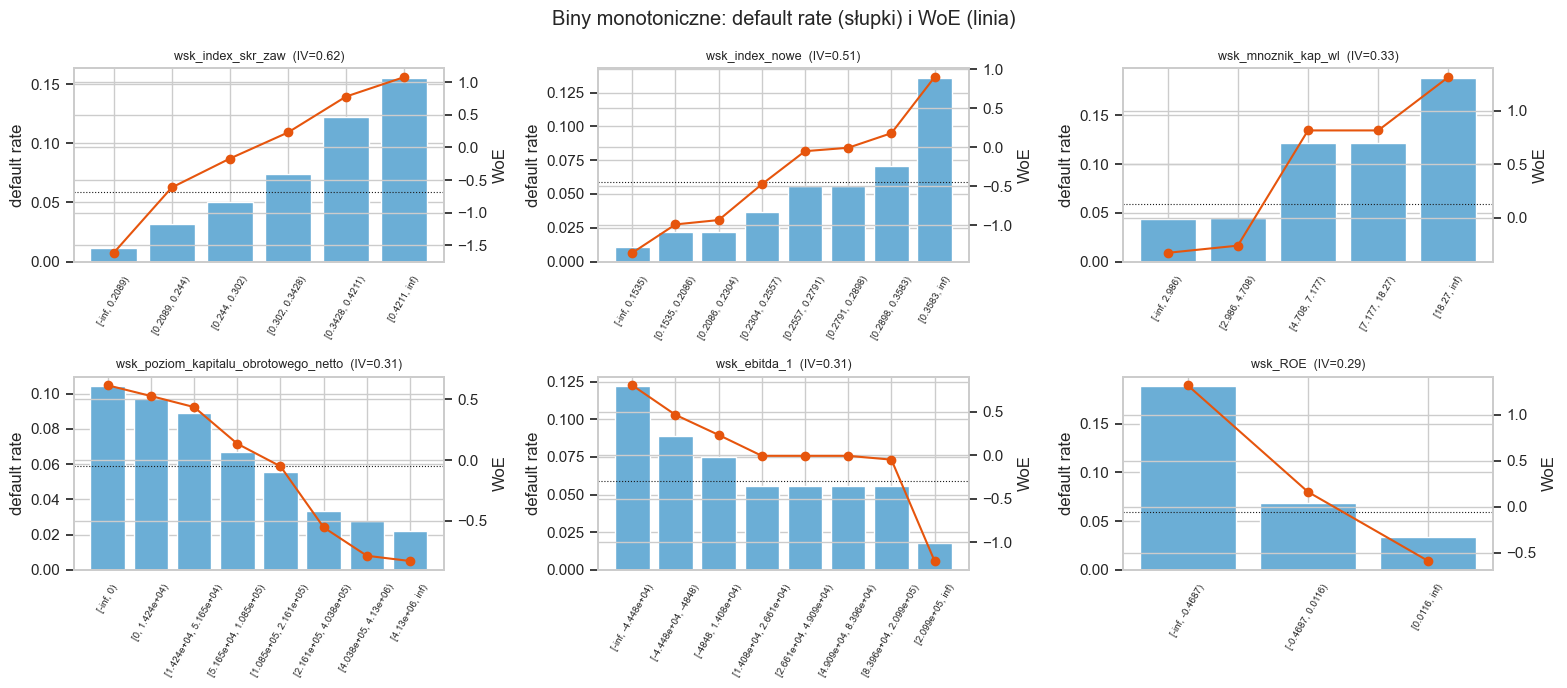

,bin,n,defaulty,default_rate,WoE
0,"[-inf, 0.2089)",437,5,0.0114,-1.6196
1,"[0.2089, 0.244)",282,9,0.0319,-0.6147
2,"[0.244, 0.302)",359,18,0.0501,-0.1703
3,"[0.302, 0.3428)",353,26,0.0737,0.2309
4,"[0.3428, 0.4211)",279,34,0.1219,0.7829
5,"[0.4211, inf)",90,14,0.1556,1.0821


In [20]:
# profilowanie binów i WoE dla najsilniejszych cech (do raportu i interpretacji modelu)
sel = iv[iv["status"] == "wybrana"].index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, c in zip(axes.ravel(), sel):
    p = fb_woe.encoder_.profile(c)
    if "default_rate" in p:
        ax.bar(range(len(p)), p["default_rate"], color="#6baed6"); ax.set_xticks(range(len(p))); ax.set_xticklabels(p["bin"], rotation=60, fontsize=7)
        ax2 = ax.twinx(); ax2.plot(range(len(p)), p["WoE"], "o-", color="#e6550d"); ax2.set_ylabel("WoE")
    else:
        ax.bar(range(len(p)), p["WoE"]); ax.set_xticks(range(len(p))); ax.set_xticklabels(p.index, rotation=60, fontsize=7)
    ax.set_title(f"{c}  (IV={iv.loc[c, 'IV']:.2f})", fontsize=9); ax.axhline(y_all[idx_train].mean(), color="k", ls=":", lw=.8); ax.set_ylabel("default rate")
plt.suptitle("Biny monotoniczne: default rate (słupki) i WoE (linia)"); plt.tight_layout(); plt.savefig("figures/woe_profiles.png", dpi=150); plt.show()
display(fb_woe.encoder_.profile(sel[0]))

In [21]:
# transformacja zbiorów: val/test dostają WYŁĄCZNIE transform() z transformerów dopasowanych na train
X_sets = {}
for name, idx in [("train", idx_train), ("val", idx_val), ("test", idx_test)]:
    X_sets[name] = {"woe": fb_woe.transform(df.iloc[idx]), "bb": fb_bb.transform(df.iloc[idx])}
    assert not X_sets[name]["woe"].isna().any().any() and not X_sets[name]["bb"].isna().any().any()
print({k: (v["woe"].shape, v["bb"].shape) for k, v in X_sets.items()})
display(X_sets["train"]["woe"].describe().T.head(8))

{'train': ((1800, 68), (1800, 237)), 'val': ((600, 68), (600, 237)), 'test': ((600, 68), (600, 237))}


,count,mean,std,min,25%,50%,75%,max
woe__wsk_index_skr_zaw,"1,800.0000",-0.3027,0.8801,-1.6196,-0.6147,-0.1703,0.2309,1.0821
woe__wsk_index_nowe,"1,800.0000",-0.2287,0.7222,-1.3520,-0.9465,-0.2626,0.1797,0.8973
woe__wsk_mnoznik_kap_wl,"1,800.0000",-0.1247,0.4744,-0.3280,-0.3280,-0.3280,-0.3112,1.3145
woe__wsk_poziom_kapitalu_obrotowego_netto,"1,800.0000",-0.1411,0.5750,-0.8300,-0.7868,-0.0506,0.4599,0.6165
woe__wsk_ebitda_1,"1,800.0000",-0.1535,0.6412,-1.2156,-0.3419,0.1129,0.2329,0.8033
woe__wsk_ROE,"1,800.0000",-0.1190,0.4939,-0.5913,-0.5913,0.1618,0.1618,1.3232
woe__wsk_rent_kaptial_podstawowy,"1,800.0000",-0.1232,0.5385,-0.9797,-0.3313,0.1343,0.1343,0.8909
woe__wsk_ebitda_3,"1,800.0000",-0.1021,0.4864,-0.6959,-0.6959,-0.1134,0.3617,0.8162


In [30]:
# Weryfikacja znaków i sensu ekonomicznego wyselekcjonowanych cech
print("Weryfikacja ekonomiczna wyselekcjonowanych cech:")
for c in sel:
    profil = fb_woe.encoder_.profile(c)
    kierunek = iv.loc[c, 'kierunek']
    
    if kierunek == 'inc':
        interpretacja = "Wraz ze wzrostem wartości cechy, ZWIĘKSZA się ryzyko defaultu (WoE rośnie)."
    elif kierunek == 'dec':
        interpretacja = "Wraz ze wzrostem wartości cechy, ZMNIEJSZA się ryzyko defaultu (WoE spada)."
    else:
        interpretacja = "Zależność niemonotoniczna lub kategoryczna."
        
    print(f"- {c}: kierunek '{kierunek}' -> {interpretacja}")

Weryfikacja ekonomiczna wyselekcjonowanych cech:
- wsk_index_skr_zaw: kierunek 'inc' -> Wraz ze wzrostem wartości cechy, ZWIĘKSZA się ryzyko defaultu (WoE rośnie).
- wsk_index_nowe: kierunek 'inc' -> Wraz ze wzrostem wartości cechy, ZWIĘKSZA się ryzyko defaultu (WoE rośnie).
- wsk_mnoznik_kap_wl: kierunek 'inc' -> Wraz ze wzrostem wartości cechy, ZWIĘKSZA się ryzyko defaultu (WoE rośnie).
- wsk_poziom_kapitalu_obrotowego_netto: kierunek 'dec' -> Wraz ze wzrostem wartości cechy, ZMNIEJSZA się ryzyko defaultu (WoE spada).
- wsk_ebitda_1: kierunek 'dec' -> Wraz ze wzrostem wartości cechy, ZMNIEJSZA się ryzyko defaultu (WoE spada).
- wsk_ROE: kierunek 'dec' -> Wraz ze wzrostem wartości cechy, ZMNIEJSZA się ryzyko defaultu (WoE spada).


## 7. Test poprawności pipeline'u: CV bez leakage i test permutacji

Cały pipeline (czyszczenie → binning/WoE → selekcja → model) jest **dopasowywany od nowa w każdym foldzie treningowym**. To tylko kontrola jakości przygotowania cech – proste modele bazowe, **nie** finalne modele ani strojenie.

**Test permutacji etykiet:** jeśli przetasujemy `default` w train i powtórzymy cały pipeline, AUC w CV musi wynosić ≈ 0,5. Wynik wyraźnie powyżej 0,5 oznaczałby przeciek informacji (np. selekcja cech na całym zbiorze).

In [22]:
def run_cv(params, model_factory, folds, y, label):
    res = []
    for k, (tr, va) in enumerate(folds, 1):
        fb = ScoringFeatureBuilder(**params).fit(df.iloc[tr], y[tr])          # fit TYLKO na foldzie treningowym
        m = model_factory().fit(fb.transform(df.iloc[tr]), y[tr])
        p = m.predict_proba(fb.transform(df.iloc[va]))[:, 1]
        res.append(dict(model=label, fold=k, AUC=roc_auc_score(y[va], p), n_cech=len(fb.feature_names_)))
    return pd.DataFrame(res)

lr  = lambda: LogisticRegression(C=0.1, max_iter=2000)
hgb = lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED)

cv_res = pd.concat([run_cv(FB_PARAMS_WOE, lr,  cv_train, y_all, "WoE + regresja logistyczna"),
                    run_cv(FB_PARAMS_BB,  hgb, cv_train, y_all, "black-box prep + HistGradientBoosting")])
display(cv_res.groupby("model").agg(AUC_srednia=("AUC", "mean"), AUC_std=("AUC", "std"), AUC_min=("AUC", "min"), AUC_max=("AUC", "max"), n_cech=("n_cech", "mean")))

# test permutacji etykiet (cały pipeline od nowa), kilka powtórzeń - pojedyncze losowanie bywa wahliwe (~20 defaultów/fold)
perm_auc = []
for r in range(5):
    y_perm = y_all.copy(); y_perm[idx_train] = np.random.default_rng(SEED + r).permutation(y_all[idx_train])
    perm_auc.append(run_cv(FB_PARAMS_WOE, lr, cv_train, y_perm, "perm")["AUC"].mean())
print("Permutacja etykiet, AUC (średnia z 5 foldów) w 5 powtórzeniach:", np.round(perm_auc, 3))
print(f"Średnio {np.mean(perm_auc):.3f} (oczekiwane ≈ 0.50; pojedyncze wyniki mogą odchylać się o ±0.05 przy tak małej liczbie defaultów)")

,AUC_srednia,AUC_std,AUC_min,AUC_max,n_cech
model,,,,,
WoE + regresja logistyczna,0.7421,0.0399,0.6977,0.7873,69.8000
black-box prep + HistGradientBoosting,0.7240,0.0439,0.6677,0.7890,231.6000


Permutacja etykiet, AUC (średnia z 5 foldów) w 5 powtórzeniach: [0.564 0.429 0.485 0.468 0.479]
Średnio 0.485 (oczekiwane ≈ 0.50; pojedyncze wyniki mogą odchylać się o ±0.05 przy tak małej liczbie defaultów)


In [23]:
# stabilność selekcji cech między foldami (ile cech powtarza się w foldach) - istotne dla stabilności modelu interpretowalnego
sel_sets = []
for tr, va in cv_train:
    f = ScoringFeatureBuilder(**FB_PARAMS_WOE).fit(df.iloc[tr], y_all[tr]); sel_sets.append(set(f.feature_names_))
freq = pd.Series([c for s in sel_sets for c in s]).value_counts()
print(f"Cechy wybrane w 5/5 foldów: {(freq == 5).sum()}, w >=3 foldach: {(freq >= 3).sum()}, w dowolnym: {len(freq)}")
jac = np.mean([len(a & b) / len(a | b) for i, a in enumerate(sel_sets) for b in sel_sets[i+1:]])
print(f"Średni Jaccard zbiorów wybranych cech między foldami: {jac:.2f}")

Cechy wybrane w 5/5 foldów: 40, w >=3 foldach: 64, w dowolnym: 107
Średni Jaccard zbiorów wybranych cech między foldami: 0.62


## 8. Zapis artefaktów i manifest (replikowalność)

In [24]:
splits = {"seed": SEED, "group_split": GROUPS is not None,
          "idx_train": idx_train.tolist(), "idx_val": idx_val.tolist(), "idx_test": idx_test.tolist(),
          "cv_train": [{"train": tr.tolist(), "val": va.tolist()} for tr, va in cv_train],
          "cv_dev":   [{"train": tr.tolist(), "val": va.tolist()} for tr, va in cv_dev]}
json.dump(splits, open(f"{ART_DIR}/splits.json", "w"))

joblib.dump({"woe": fb_woe, "blackbox": fb_bb}, f"{ART_DIR}/feature_builders.joblib")
iv.to_csv(f"{ART_DIR}/iv_table.csv")
for name in ("train", "val", "test"):
    X_sets[name]["woe"].assign(**{TARGET: y_all[{"train": idx_train, "val": idx_val, "test": idx_test}[name]]}).to_csv(f"{ART_DIR}/X_{name}_woe.csv")
    X_sets[name]["bb"].assign(**{TARGET: y_all[{"train": idx_train, "val": idx_val, "test": idx_test}[name]]}).to_csv(f"{ART_DIR}/X_{name}_bb.csv")

manifest = {
    "data_file": DATA_PATH, "data_md5": hashlib.md5(open(DATA_PATH, "rb").read()).hexdigest(),
    "n_obs": len(df), "n_defaults": int(y_all.sum()), "seed": SEED,
    "split": {"train": len(idx_train), "val": len(idx_val), "test": len(idx_test), "cv_folds": N_FOLDS},
    "feature_params_woe": {k: v for k, v in FB_PARAMS_WOE.items() if k not in ("num_cols", "cat_cols")},
    "feature_params_blackbox": {k: v for k, v in FB_PARAMS_BB.items() if k not in ("num_cols", "cat_cols")},
    "drop_suspicious": DROP_SUSPICIOUS, "cat_cols": CAT_COLS,
    "features_woe": fb_woe.feature_names_, "n_features_blackbox": len(fb_bb.feature_names_),
    "dropped_missing": fb_bb.cleaner_.dropped_["za_duzo_brakow"], "dropped_quasi_const": fb_bb.cleaner_.dropped_["quasi_stale"],
    "cv_auc_check": cv_res.groupby("model")["AUC"].agg(["mean", "std"]).round(4).to_dict("index"),
    "permutation_auc_mean": round(float(np.mean(perm_auc)), 4),
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__}}
json.dump(manifest, open(f"{ART_DIR}/feature_manifest.json", "w"), indent=2, ensure_ascii=False)
print("Zapisano:", sorted(os.listdir(ART_DIR)))

Zapisano: ['X_test_bb.csv', 'X_test_woe.csv', 'X_train_bb.csv', 'X_train_woe.csv', 'X_val_bb.csv', 'X_val_woe.csv', 'feature_builders.joblib', 'feature_manifest.json', 'iv_table.csv', 'splits.json']


### Co dalej
* Notebook 02 – model interpretowalny (regresja logistyczna na cechach WoE: współczynniki, VIF, PDP/dekompozycja logitu) i model black-box (tuning w `cv_train`, SHAP/LIME): wczytaj `artifacts/splits.json` i `artifacts/feature_builders.joblib`.
* Notebook 03 – kalibracja (Platt/izotoniczna na `val` lub OOF z `cv_dev`), dostosowanie do PD = 4%, progi i ratingi.
* Jeśli w ostatecznym treningu połączysz train+val, **dopasuj transformery od nowa** na połączonych danych (nigdy na teście).